In [1]:
x=1

In [2]:
import scanpy as sc
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt


/lustre/groups/ml01/workspace/anastasia.litinetskaya/mambaforge/envs/sc/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning: Importing read_csv from `anndata` is deprecated. Import anndata.io.read_csv instead.
  warnings.warn(msg, FutureWarning)
/lustre/groups/ml01/workspace/anastasia.litinetskaya/mambaforge/envs/sc/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning: Importing read_text from `anndata` is deprecated. Import anndata.io.read_text instead.
  warnings.warn(msg, FutureWarning)
/lustre/groups/ml01/workspace/anastasia.litinetskaya/mambaforge/envs/sc/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning: Importing read_excel from `anndata` is deprecated. Import anndata.io.read_excel instead.
  warnings.warn(msg, FutureWarning)
/lustre/groups/ml01/workspace/anastasia.litinetskaya/mambaforge/envs/sc/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning: Importing read_mtx from `anndata` is deprecated. Import anndata.io.read_mtx ins

## scvi final

In [6]:
df = pd.read_csv('/lustre/groups/ml01/projects/2022_multigrate_anastasia.litinetskaya/multimil_reproducibility/pipeline_mil/data/reports/pbmc_scvi/best.csv', sep='\t', index_col=None)
df

,hash,accuracy,best_params,best_epoch,best_query_epoch,accuracies,method,task
0,64b341e21a,0.642857,{'norm': 0},NaN,NaN,"[0.625, 0.875, 0.5, 0.5, 0.7142857142857143]",ct_pb_mr,pbmc_scvi
1,319d1a19ad,0.542857,"{'norm': 0, 'epochs': 200, 'lr': 0.001, 'batch...",NaN,NaN,"[0.25, 0.875, 0.5, 0.375, 0.7142857142857143]",ct_pb_nn,pbmc_scvi
2,00692090c0,0.600000,{'norm': 0},NaN,NaN,"[0.125, 0.875, 0.5, 0.5, 1.0]",ct_pb_rf,pbmc_scvi
3,610bc42612,0.410714,{'norm': 0},NaN,NaN,"[0.625, 0.5, 0.25, 0.25, 0.4285714285714285]",freq_mr,pbmc_scvi
4,8353316bef,0.457143,"{'norm': 0, 'epochs': 200, 'lr': 0.001, 'batch...",NaN,NaN,"[0.375, 0.875, 0.375, 0.375, 0.2857142857142857]",freq_nn,pbmc_scvi
5,fa5d48eac7,0.642857,{'norm': 0},NaN,NaN,"[0.375, 0.875, 0.5, 0.75, 0.7142857142857143]",freq_rf,pbmc_scvi
6,73026bce71,0.374206,"{'norm': 0, 'epochs': 30, 'lr': 0.0001, 'batch...",NaN,NaN,"[0.3699832775919732, 0.2763730324043557, 0.437...",gex_nn,pbmc_scvi
7,ae574b66bf,0.523120,{'norm': 0},NaN,NaN,"[0.4896791387959866, 0.5156748490521265, 0.538...",gex_rf,pbmc_scvi
8,a1c88f2246,0.823074,"{'lr': 0.0001, 'categorical_covariate_keys': ""...",49.0,NaN,"[0.8597669314381271, 0.9208743111767342, 0.657...",multigrate_mil,pbmc_scvi
9,6e49b5e194,0.837781,"{'lr': 0.001, 'categorical_covariate_keys': ""[...",49.0,NaN,"[0.8141461120401338, 0.8673504363645952, 0.766...",multigrate_mil_reg,pbmc_scvi


In [7]:
task = 'pbmc_scvi'
runs = {}
yerr = {}
df_task = df[df['task'] == task]
for method in np.unique(df_task['method']):
    runs[method] = eval(df_task.loc[df_task['method'] == method, 'accuracies'].values[0])
    yerr[method] = np.array(runs[method]).std()

df_tmp = df_task[['method', 'accuracy']]
df_tmp.index = df_tmp['method']
df_tmp = df_tmp[['accuracy']].sort_values('accuracy', ascending=False)
df_tmp = df_tmp.T

df_tmp = df_tmp[['multigrate_mil_reg', 'multigrate_mil', 'ct_pb_mr', 'ct_pb_rf', 'ct_pb_nn', 'freq_rf', 'freq_nn', 'freq_mr', 'pb_rf', 'pb_nn', 'gex_rf', 'gex_nn']]

yerr_sorted = [yerr[method] for method in df_tmp.columns]

In [8]:
df_tmp.columns

Index(['multigrate_mil_reg', 'multigrate_mil', 'ct_pb_mr', 'ct_pb_rf',
       'ct_pb_nn', 'freq_rf', 'freq_nn', 'freq_mr', 'pb_rf', 'pb_nn', 'gex_rf',
       'gex_nn'],
      dtype='object', name='method')

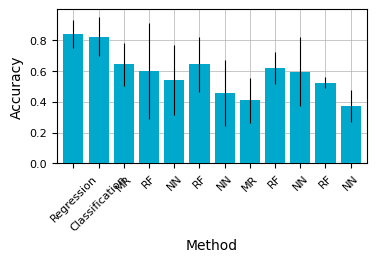

In [9]:
ax = df_tmp.T.plot(kind='bar', zorder=3, figsize=(4, 2), color=["#00a8cc"], rot=45, yerr=yerr_sorted, width=0.8, fontsize=8, error_kw=dict(lw=0.8))
ax.get_legend().remove()
ax.grid(zorder=0, linewidth=0.5)
ax.set_xticklabels([
    'Regression', 'Classification', # multimil
    'MR', 'RF', 'NN', # ct pb
    'RF', 'NN', 'MR', # freq
    'RF', 'NN', # pb
    'RF', 'NN'] # gex
    , rotation=45)
plt.xlabel('Method')
plt.ylabel('Accuracy')
plt.title('')
plt.savefig('figures/pbmc_accuracy_scvi_3cond.svg', bbox_inches='tight')

## scvi final binary

In [10]:
df = pd.read_csv('/lustre/groups/ml01/projects/2022_multigrate_anastasia.litinetskaya/multimil_reproducibility/pipeline_mil/data/reports/pbmc_scvi_binary/best.csv', sep='\t', index_col=None)
df

,hash,accuracy,best_params,best_epoch,best_query_epoch,accuracies,method,task
0,77b4b010f3,0.911067,{'norm': 0},NaN,NaN,"[0.8260869565217391, 0.9565217391304348, 1.0, ...",ct_pb_mr,pbmc_scvi_binary
1,76cc1e7707,0.883794,"{'norm': 0, 'epochs': 200, 'lr': 0.0001, 'batc...",NaN,NaN,"[0.8260869565217391, 1.0, 0.9565217391304348, ...",ct_pb_nn,pbmc_scvi_binary
2,2d004441ab,0.875494,{'norm': 0},NaN,NaN,"[0.9130434782608696, 1.0, 0.782608695652174, 1...",ct_pb_rf,pbmc_scvi_binary
3,a243526f6c,0.744269,{'norm': 0},NaN,NaN,"[0.8260869565217391, 0.5652173913043478, 0.739...",freq_mr,pbmc_scvi_binary
4,71576acfd2,0.822925,"{'norm': 0, 'epochs': 200, 'lr': 0.001, 'batch...",NaN,NaN,"[0.8260869565217391, 0.8695652173913043, 0.782...",freq_nn,pbmc_scvi_binary
5,2a404bf6c3,0.858103,{'norm': 0},NaN,NaN,"[0.9565217391304348, 0.9130434782608696, 0.739...",freq_rf,pbmc_scvi_binary
6,74d849caf6,0.844465,"{'norm': 0, 'epochs': 30, 'lr': 1e-05, 'batch_...",NaN,NaN,"[0.9101296589424882, 0.7758175332548455, 0.777...",gex_nn,pbmc_scvi_binary
7,98591c83aa,0.862400,{'norm': 0},NaN,NaN,"[0.9002863049363815, 0.8288583528088703, 0.811...",gex_rf,pbmc_scvi_binary
8,f00b2ca842,0.947941,"{'lr': 0.0001, 'categorical_covariate_keys': ""...",49.0,NaN,"[0.9548658864640908, 0.9763833488551898, 0.923...",multigrate_mil,pbmc_scvi_binary
9,54207b5150,0.949209,"{'lr': 1e-05, 'categorical_covariate_keys': ""[...",49.0,NaN,"[0.92557801593274, 0.983754766381416, 0.943200...",multigrate_mil_reg,pbmc_scvi_binary


In [12]:
task = 'pbmc_scvi_binary'
runs = {}
yerr = {}
df_task = df[df['task'] == task]
for method in np.unique(df_task['method']):
    runs[method] = eval(df_task.loc[df_task['method'] == method, 'accuracies'].values[0])
    yerr[method] = np.array(runs[method]).std()

df_tmp = df_task[['method', 'accuracy']]
df_tmp.index = df_tmp['method']
df_tmp = df_tmp[['accuracy']].sort_values('accuracy', ascending=False)
df_tmp = df_tmp.T
yerr_sorted = [yerr[method] for method in df_tmp.columns]
df_tmp.rename(columns={
    'multigrate_mil_reg': 'multimil_reg',
    'multigrate_mil': 'multimil_class',}, inplace=True)

In [13]:
df_tmp.columns

Index(['multimil_reg', 'multimil_class', 'pb_mr', 'ct_pb_mr', 'pb_nn', 'pb_rf',
       'ct_pb_nn', 'ct_pb_rf', 'gex_rf', 'freq_rf', 'gex_nn', 'freq_nn',
       'freq_mr'],
      dtype='object', name='method')

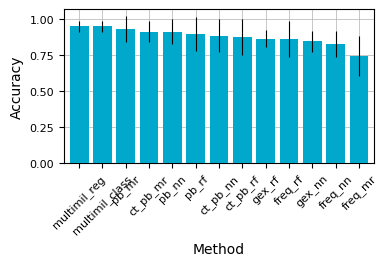

In [14]:
ax = df_tmp.T.plot(kind='bar', zorder=3, figsize=(4, 2), color=["#00a8cc"], rot=45, yerr=yerr_sorted, width=0.8, fontsize=8, error_kw=dict(lw=0.8))
ax.get_legend().remove()
ax.grid(zorder=0, linewidth=0.5)
plt.xlabel('Method')
plt.ylabel('Accuracy')
plt.title('')
plt.savefig('figures/pbmc_accuracy_scvi_binary.svg', bbox_inches='tight')

## scvi 6 classes

In [15]:
## scvi final
df = pd.read_csv('/lustre/groups/ml01/projects/2022_multigrate_anastasia.litinetskaya/multimil_reproducibility/pipeline_mil/data/reports/pbmc_scvi_6_class/best.csv', sep='\t', index_col=None)
df

,hash,accuracy,best_params,best_epoch,best_query_epoch,accuracies,method,task
0,583baa3d1e,0.441502,{'norm': 0},NaN,NaN,"[0.4347826086956521, 0.4782608695652174, 0.521...",ct_pb_mr,pbmc_scvi_6_class
1,e1a934162f,0.396047,"{'norm': 0, 'epochs': 200, 'lr': 0.001, 'batch...",NaN,NaN,"[0.2608695652173913, 0.6086956521739131, 0.565...",ct_pb_nn,pbmc_scvi_6_class
2,2b1a835eb2,0.460079,{'norm': 0},NaN,NaN,"[0.391304347826087, 0.5652173913043478, 0.4347...",ct_pb_rf,pbmc_scvi_6_class
3,7ee579e9df,0.159289,{'norm': 0},NaN,NaN,"[0.0869565217391304, 0.1739130434782608, 0.217...",freq_mr,pbmc_scvi_6_class
4,6b43146f2a,0.247826,"{'norm': 0, 'epochs': 200, 'lr': 0.001, 'batch...",NaN,NaN,"[0.217391304347826, 0.217391304347826, 0.30434...",freq_nn,pbmc_scvi_6_class
5,2657fdf7b3,0.362846,{'norm': 0},NaN,NaN,"[0.3478260869565217, 0.3043478260869565, 0.434...",freq_rf,pbmc_scvi_6_class
6,818880425e,0.311222,"{'norm': 0, 'epochs': 30, 'lr': 1e-05, 'batch_...",NaN,NaN,"[0.4216553788134347, 0.2678926004674128, 0.270...",gex_nn,pbmc_scvi_6_class
7,828a422cd2,0.338142,{'norm': 0},NaN,NaN,"[0.2886836027713625, 0.3939271468484774, 0.368...",gex_rf,pbmc_scvi_6_class
8,bffd5965fc,0.502382,"{'lr': 0.001, 'categorical_covariate_keys': ""[...",49.0,NaN,"[0.4332805701879579, 0.6780210511518389, 0.589...",multigrate_mil,pbmc_scvi_6_class
9,1eb43a7dcb,0.441690,"{'lr': 0.001, 'categorical_covariate_keys': ""[...",99.0,NaN,"[0.3946, 0.46685, 0.6003, 0.4301, 0.3166]",multigrate_mil_reg,pbmc_scvi_6_class


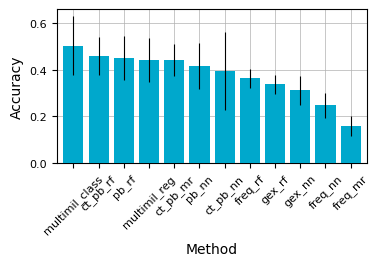

In [17]:
task = 'pbmc_scvi_6_class'
runs = {}
yerr = {}
df_task = df[df['task'] == task]
for method in np.unique(df_task['method']):
    runs[method] = eval(df_task.loc[df_task['method'] == method, 'accuracies'].values[0])
    yerr[method] = np.array(runs[method]).std()

df_tmp = df_task[['method', 'accuracy']]
df_tmp.index = df_tmp['method']
df_tmp = df_tmp[['accuracy']].sort_values('accuracy', ascending=False)
df_tmp = df_tmp.T

yerr_sorted = [yerr[method] for method in df_tmp.columns]

df_tmp.rename(columns={
    'multigrate_mil_reg': 'multimil_reg',
    'multigrate_mil': 'multimil_class',}, inplace=True)

df_tmp.columns
ax = df_tmp.T.plot(kind='bar', zorder=3, figsize=(4, 2), color=["#00a8cc"], rot=45, yerr=yerr_sorted, width=0.8, fontsize=8, error_kw=dict(lw=0.8))
ax.get_legend().remove()
ax.grid(zorder=0, linewidth=0.5)

plt.xlabel('Method')
plt.ylabel('Accuracy')
plt.title('')
plt.savefig('figures/pbmc_accuracy_scvi_6classes.svg', bbox_inches='tight')

## sample covs accuracies

In [3]:
df = pd.read_csv('/lustre/groups/ml01/projects/2022_multigrate_anastasia.litinetskaya/multimil_reproducibility/pipeline_mil/data/reports/pbmc_scvi/best.csv', sep='\t', index_col=None)
df

,hash,accuracy,best_params,best_epoch,best_query_epoch,accuracies,method,task
0,64b341e21a,0.642857,{'norm': 0},NaN,NaN,"[0.625, 0.875, 0.5, 0.5, 0.7142857142857143]",ct_pb_mr,pbmc_scvi
1,319d1a19ad,0.542857,"{'norm': 0, 'epochs': 200, 'lr': 0.001, 'batch...",NaN,NaN,"[0.25, 0.875, 0.5, 0.375, 0.7142857142857143]",ct_pb_nn,pbmc_scvi
2,00692090c0,0.600000,{'norm': 0},NaN,NaN,"[0.125, 0.875, 0.5, 0.5, 1.0]",ct_pb_rf,pbmc_scvi
3,610bc42612,0.410714,{'norm': 0},NaN,NaN,"[0.625, 0.5, 0.25, 0.25, 0.4285714285714285]",freq_mr,pbmc_scvi
4,8353316bef,0.457143,"{'norm': 0, 'epochs': 200, 'lr': 0.001, 'batch...",NaN,NaN,"[0.375, 0.875, 0.375, 0.375, 0.2857142857142857]",freq_nn,pbmc_scvi
5,fa5d48eac7,0.642857,{'norm': 0},NaN,NaN,"[0.375, 0.875, 0.5, 0.75, 0.7142857142857143]",freq_rf,pbmc_scvi
6,73026bce71,0.374206,"{'norm': 0, 'epochs': 30, 'lr': 0.0001, 'batch...",NaN,NaN,"[0.3699832775919732, 0.2763730324043557, 0.437...",gex_nn,pbmc_scvi
7,ae574b66bf,0.523120,{'norm': 0},NaN,NaN,"[0.4896791387959866, 0.5156748490521265, 0.538...",gex_rf,pbmc_scvi
8,a1c88f2246,0.823074,"{'lr': 0.0001, 'categorical_covariate_keys': ""...",49.0,NaN,"[0.8597669314381271, 0.9208743111767342, 0.657...",multigrate_mil,pbmc_scvi
9,6e49b5e194,0.837781,"{'lr': 0.001, 'categorical_covariate_keys': ""[...",49.0,NaN,"[0.8141461120401338, 0.8673504363645952, 0.766...",multigrate_mil_reg,pbmc_scvi


In [19]:
task = 'pbmc_scvi'
runs = {}
yerr = {}
df_task = df[df['task'] == task]
for method in np.unique(df_task['method']):
    runs[method] = eval(df_task.loc[df_task['method'] == method, 'accuracies'].values[0])
    yerr[method] = np.array(runs[method]).std()

df_tmp = df_task[['method', 'accuracy']]
df_tmp.index = df_tmp['method']
df_tmp = df_tmp[['accuracy']].sort_values('accuracy', ascending=False)
df_tmp = df_tmp.T

df_tmp = df_tmp[['multigrate_mil_reg', 'multigrate_mil']]

yerr_sorted = [yerr[method] for method in df_tmp.columns]

In [20]:
df_tmp

method,multigrate_mil_reg,multigrate_mil
accuracy,0.837781,0.823074


In [21]:
yerr_sorted

[0.09190398977389215, 0.12878501701004322]

In [22]:
# sex only
df_tmp['Regression Sex'] = 0.7794586624068953
df_tmp['Classification Sex'] = 0.7467288677159054
# age only
df_tmp['Classification Age'] = 0.679409216125264
df_tmp['Regression Age'] = 0.6773621618368459
# sex and age
df_tmp['Regression Sex and Age'] = 0.6387340628075562
df_tmp['Classification Sex and Age'] = 0.579745070144736
df_tmp

method,multigrate_mil_reg,multigrate_mil,Regression Sex,Classification Sex,Classification Age,Regression Age,Regression Sex and Age,Classification Sex and Age
accuracy,0.837781,0.823074,0.779459,0.746729,0.679409,0.677362,0.638734,0.579745


In [23]:
yerr_sorted.extend([
    0.1175311688963237,
    0.16381781554649125,
    0.24966880429689853,
    0.12998959189303502,
    0.21576227206998824,
    0.2083206279791663,
])
yerr_sorted

[0.09190398977389215,
 0.12878501701004322,
 0.1175311688963237,
 0.16381781554649125,
 0.24966880429689853,
 0.12998959189303502,
 0.21576227206998824,
 0.2083206279791663]

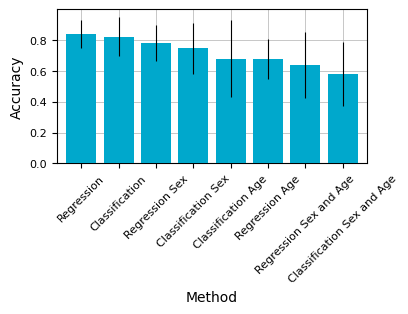

In [25]:
ax = df_tmp.T.plot(kind='bar', zorder=3, figsize=(4, 2), color=["#00a8cc"], rot=45, yerr=yerr_sorted, width=0.8, fontsize=8, error_kw=dict(lw=0.8))
ax.get_legend().remove()
ax.grid(zorder=0, linewidth=0.5)
ax.set_xticklabels([
    'Regression', 'Classification', # no covs
    'Regression Sex', 'Classification Sex', # Sex
    'Classification Age', 'Regression Age',  # Age
    'Regression Sex and Age', 'Classification Sex and Age', # both]    
    ],
    rotation=45)
plt.xlabel('Method')
plt.ylabel('Accuracy')
plt.title('')
plt.savefig('figures/pbmc_accuracy_scvi_3cond_sample_covariates.svg', bbox_inches='tight')